# Data cleaning – SAIL2025 LVMA pedestrian counts
In this notebook the LVMA pedestrian count data (3-minute intervals) is loaded, inspected and cleaned, 
so it can be used for further analysis of peaks and sudden changes in pedestrian flows.

## 1. Loading and first inspection
The LVMA dataset is loaded with pandas. We first inspect its size, 
the first and last rows, the column names and data types, 
to understand the structure of the data before cleaning it.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../Data/SAIL2025_LVMA_data_3min_20August-25August2025_flow.csv")

In [3]:
df.shape

(2400, 81)

In [4]:
df.head()

,timestamp,CMSA-GAKH-01_0,CMSA-GAKH-01_180,CMSA-GAWW-11_120,CMSA-GAWW-11_300,CMSA-GAWW-12_115,CMSA-GAWW-12_295,CMSA-GAWW-13_120,CMSA-GAWW-13_300,CMSA-GAWW-14_40,...,GVCV-13_10,GVCV-13_190,GVCV-14_90,GVCV-14_270,hour,minute,day,month,weekday,is_weekend
0,2025-08-20 00:00:00+02:00,15,4,29,33,44,28,42,37,11,...,41,40,0,0,0,0,20,8,2,0
1,2025-08-20 00:03:00+02:00,1,3,21,29,34,39,9,14,6,...,0,0,0,0,0,3,20,8,2,0
2,2025-08-20 00:06:00+02:00,5,4,35,22,29,34,33,42,14,...,0,0,0,0,0,6,20,8,2,0
3,2025-08-20 00:09:00+02:00,4,4,40,47,42,40,19,34,15,...,0,0,0,0,0,9,20,8,2,0
4,2025-08-20 00:12:00+02:00,4,11,54,59,58,33,17,33,26,...,127,57,0,0,0,12,20,8,2,0


In [5]:
df.tail()

,timestamp,CMSA-GAKH-01_0,CMSA-GAKH-01_180,CMSA-GAWW-11_120,CMSA-GAWW-11_300,CMSA-GAWW-12_115,CMSA-GAWW-12_295,CMSA-GAWW-13_120,CMSA-GAWW-13_300,CMSA-GAWW-14_40,...,GVCV-13_10,GVCV-13_190,GVCV-14_90,GVCV-14_270,hour,minute,day,month,weekday,is_weekend
2395,2025-08-24 23:45:00+02:00,11,9,38,44,51,51,6,19,18,...,10,12,0,0,23,45,24,8,6,1
2396,2025-08-24 23:48:00+02:00,2,1,46,42,30,45,34,33,8,...,1,6,23,6,23,48,24,8,6,1
2397,2025-08-24 23:51:00+02:00,10,2,51,26,42,59,21,30,22,...,0,0,0,8,23,51,24,8,6,1
2398,2025-08-24 23:54:00+02:00,3,1,24,36,42,32,12,55,9,...,0,0,2,8,23,54,24,8,6,1
2399,2025-08-24 23:57:00+02:00,6,1,38,65,56,41,21,45,10,...,79,2,1,2,23,57,24,8,6,1


In [6]:
df.columns.tolist()

['timestamp',
 'CMSA-GAKH-01_0',
 'CMSA-GAKH-01_180',
 'CMSA-GAWW-11_120',
 'CMSA-GAWW-11_300',
 'CMSA-GAWW-12_115',
 'CMSA-GAWW-12_295',
 'CMSA-GAWW-13_120',
 'CMSA-GAWW-13_300',
 'CMSA-GAWW-14_40',
 'CMSA-GAWW-14_220',
 'CMSA-GAWW-15_30',
 'CMSA-GAWW-15_210',
 'CMSA-GAWW-16_30',
 'CMSA-GAWW-16_210',
 'CMSA-GAWW-17_40',
 'CMSA-GAWW-17_220',
 'CMSA-GAWW-19_115',
 'CMSA-GAWW-19_295',
 'CMSA-GAWW-20_120',
 'CMSA-GAWW-20_300',
 'CMSA-GAWW-21_120',
 'CMSA-GAWW-21_300',
 'CMSA-GAWW-23_109',
 'CMSA-GAWW-23_289',
 'GACM-04_50',
 'GACM-04_230',
 'GASA-01-A1_135',
 'GASA-01-A1_315',
 'GASA-01-A2_135',
 'GASA-01-A2_315',
 'GASA-01-B_135',
 'GASA-01-B_315',
 'GASA-01-C_135',
 'GASA-01-C_315',
 'GASA-02-01_135',
 'GASA-02-01_315',
 'GASA-02-02_135',
 'GASA-02-02_315',
 'GASA-03_105',
 'GASA-03_285',
 'GASA-04_135',
 'GASA-04_315',
 'GASA-05-O_135',
 'GASA-05-O_315',
 'GASA-05-W_135',
 'GASA-05-W_315',
 'GASA-06_95',
 'GASA-06_275',
 'GASA-06-B_95',
 'GASA-06-B_275',
 'GVCV-01_40',
 'GVCV-01_220',


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 81 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   timestamp         2400 non-null   str  
 1   CMSA-GAKH-01_0    2400 non-null   int64
 2   CMSA-GAKH-01_180  2400 non-null   int64
 3   CMSA-GAWW-11_120  2400 non-null   int64
 4   CMSA-GAWW-11_300  2400 non-null   int64
 5   CMSA-GAWW-12_115  2400 non-null   int64
 6   CMSA-GAWW-12_295  2400 non-null   int64
 7   CMSA-GAWW-13_120  2400 non-null   int64
 8   CMSA-GAWW-13_300  2400 non-null   int64
 9   CMSA-GAWW-14_40   2400 non-null   int64
 10  CMSA-GAWW-14_220  2400 non-null   int64
 11  CMSA-GAWW-15_30   2400 non-null   int64
 12  CMSA-GAWW-15_210  2400 non-null   int64
 13  CMSA-GAWW-16_30   2400 non-null   int64
 14  CMSA-GAWW-16_210  2400 non-null   int64
 15  CMSA-GAWW-17_40   2400 non-null   int64
 16  CMSA-GAWW-17_220  2400 non-null   int64
 17  CMSA-GAWW-19_115  2400 non-null   int64
 18 

**First inspection**

- The dataset contains **2400 rows and 81 columns**. Each row represents one 3-minute interval.
- The data covers **20 August 2025 00:00 to 24 August 2025 23:57** (5 full days × 480 intervals = 2400 rows). 
  Note: despite the file name ("20August-25August"), no measurements from 25 August are included.
- The columns consist of: 1 `timestamp` column, 74 sensor columns and 6 time-related helper columns 
  (`hour`, `minute`, `day`, `month`, `weekday`, `is_weekend`).
- `timestamp` is stored as **text (str)** and needs to be converted to a datetime type before it can be used for time-based analysis.
- At first sight there are no missing values (2400 non-null), but this will be checked for all columns in a later step.

## 2. Understanding the columns
The sensor columns have names like `CMSA-GAWW-11_120`. In this step we separate the sensor columns 
from the time columns, and find out how many sensors there are and what the number after the underscore means.

In [8]:
time_cols = ['hour', 'minute', 'day', 'month', 'weekday', 'is_weekend']

sensor_cols = [col for col in df.columns if col not in time_cols and col != 'timestamp']

len(sensor_cols)

74

In [9]:
sensor_ids = [col.split('_')[0] for col in sensor_cols]
directions = [col.split('_')[1] for col in sensor_cols]

print(sensor_ids[:6])
print(directions[:6])

['CMSA-GAKH-01', 'CMSA-GAKH-01', 'CMSA-GAWW-11', 'CMSA-GAWW-11', 'CMSA-GAWW-12', 'CMSA-GAWW-12']
['0', '180', '120', '300', '115', '295']


In [10]:
sensor_counts = pd.Series(sensor_ids).value_counts()

print("Number of unique sensors:", len(sensor_counts))
print(sensor_counts.value_counts())

Number of unique sensors: 37
count
2    37
Name: count, dtype: int64


In [11]:
for sensor in ['CMSA-GAWW-11', 'GASA-03', 'GVCV-13']:
    print(sensor, [col for col in sensor_cols if col.startswith(sensor + '_')])

CMSA-GAWW-11 ['CMSA-GAWW-11_120', 'CMSA-GAWW-11_300']
GASA-03 ['GASA-03_105', 'GASA-03_285']
GVCV-13 ['GVCV-13_10', 'GVCV-13_190']


**Findings – columns**

- The dataset contains **74 sensor columns** belonging to **37 unique sensors**.
- Each column name has the format `SENSORID_DIRECTION`. The number after the underscore is the 
  **walking direction in degrees** (compass bearing: 0° = north, 90° = east, 180° = south, 270° = west).
- Every sensor has exactly **two columns with directions 180° apart**: the sensor counts pedestrians 
  in both opposite directions of the same path.
- The total pedestrian flow at a sensor location is therefore the **sum of both directions**. 
  Both the directional and total flows can be useful: two-way flows of similar size may indicate 
  conflicting crowd movements.
- Sensor ID prefixes indicate groups of locations: `CMSA-` (city centre streets), `GACM`, `GVCV` (ferry landings) and `GASA` 
  (SAIL area, e.g. IJ-boulevard, Oosterdoksbrug); the exact names are in `sensor-location.xlsx`.

## 3. Checking the timestamps
The `timestamp` column is currently stored as text. We convert it to a datetime type, 
and check whether the measurements are complete, unique, in the right order and exactly 3 minutes apart.

In [12]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

df['timestamp'].dtype

datetime64[us, UTC+02:00]

In [13]:
print("First measurement:", df['timestamp'].min())
print("Last measurement: ", df['timestamp'].max())

First measurement: 2025-08-20 00:00:00+02:00
Last measurement:  2025-08-24 23:57:00+02:00


In [14]:
df['timestamp'].duplicated().sum()

np.int64(0)

In [15]:
df['timestamp'].diff().value_counts()

timestamp
0 days 00:03:00    2399
Name: count, dtype: int64

In [16]:
expected_times = pd.date_range(start=df['timestamp'].min(), 
                               end=df['timestamp'].max(), 
                               freq='3min')

missing_times = expected_times.difference(df['timestamp'])

print("Expected number of timestamps:", len(expected_times))
print("Missing timestamps:", len(missing_times))

Expected number of timestamps: 2400
Missing timestamps: 0


In [17]:
df['timestamp'].is_monotonic_increasing

True

In [18]:
print("hour ok:      ", (df['hour'] == df['timestamp'].dt.hour).all())
print("minute ok:    ", (df['minute'] == df['timestamp'].dt.minute).all())
print("day ok:       ", (df['day'] == df['timestamp'].dt.day).all())
print("weekday ok:   ", (df['weekday'] == df['timestamp'].dt.weekday).all())
print("is_weekend ok:", (df['is_weekend'] == (df['timestamp'].dt.weekday >= 5).astype(int)).all())

hour ok:       True
minute ok:     True
day ok:        True
weekday ok:    True
is_weekend ok: True


**Findings – timestamps**

- `timestamp` was converted from text to a datetime type (time zone UTC+02:00, Dutch summer time).
- The measurements run from **20 August 2025 00:00 to 24 August 2025 23:57**.
- There are **no duplicate timestamps** and the data is in **chronological order**.
- All consecutive measurements are exactly **3 minutes apart**, and compared to a complete 3-minute 
  time range **no timestamps are missing** (2400 of 2400 present).
- The helper columns (`hour`, `minute`, `day`, `weekday`, `is_weekend`) are **consistent** with the timestamp.
- Conclusion: the time dimension of the dataset is complete and reliable; no corrections are needed.

## 4. Missing values and duplicates
We check whether any sensor measurements are missing, whether any rows or sensor columns 
appear twice, and whether all sensor values are stored as whole numbers (counts).

In [19]:
print("Total missing values:", df.isna().sum().sum())

Total missing values: 0


In [20]:
missing_per_column = df.isna().sum()

missing_per_column[missing_per_column > 0]

Series([], dtype: int64)

In [21]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [22]:
duplicate_columns = df[sensor_cols].T.duplicated()

print("Duplicate sensor columns:", duplicate_columns.sum())

Duplicate sensor columns: 0


In [23]:
df[sensor_cols].dtypes.value_counts()

int64    74
Name: count, dtype: int64

**Findings – missing values and duplicates**

- The dataset contains **no missing values (NaN)** in any column.
- There are **no duplicate rows** and **no duplicate sensor columns** (no two sensors have identical measurements).
- All 74 sensor columns are stored as **integers**, which is consistent with pedestrian counts.
- Note: a sensor that is not working may still record a value of **0** instead of a missing value. 
  Zero values are therefore not automatically reliable, and are analysed further in the next step.

## 5. Unusual values and sensor malfunctions
Zero values and extreme values are not automatically correct. In this step we check for impossible values, 
sensors that (almost) never record anything, sensors that suddenly stop working, and extreme peaks.

In [24]:
print("Negative values:", (df[sensor_cols] < 0).sum().sum())

Negative values: 0


In [25]:
df[sensor_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
CMSA-GAKH-01_0,2400.0,57.513750,69.204386,0.0,3.0,17.0,110.25,266.0
CMSA-GAKH-01_180,2400.0,49.180000,58.768898,0.0,2.0,15.0,95.00,257.0
CMSA-GAWW-11_120,2400.0,37.840417,36.631952,0.0,6.0,30.0,59.00,246.0
CMSA-GAWW-11_300,2400.0,37.500417,33.478431,0.0,6.0,32.0,61.00,156.0
CMSA-GAWW-12_115,2400.0,39.021250,34.266092,0.0,7.0,32.0,62.00,168.0
...,...,...,...,...,...,...,...,...
GVCV-11_230,2400.0,26.324167,58.907717,0.0,0.0,0.0,15.25,396.0
GVCV-13_10,2400.0,32.629583,67.133867,0.0,0.0,1.0,26.00,396.0
GVCV-13_190,2400.0,28.449583,53.724243,0.0,0.0,1.0,35.00,339.0
GVCV-14_90,2400.0,24.782083,57.345319,0.0,0.0,0.0,7.00,381.0


In [26]:
zero_pct = (df[sensor_cols] == 0).mean() * 100

zero_pct.sort_values(ascending=False).head(15).round(1)

GASA-06_95       99.9
GASA-06_275      99.8
GVCV-09_80       98.7
GVCV-09_260      98.7
GVCV-08_225      80.7
GVCV-07_230      79.4
GVCV-07_50       78.8
GVCV-08_45       78.1
GVCV-06_95       75.0
GVCV-06_275      73.9
GASA-06-B_95     68.2
GASA-06-B_275    68.0
GVCV-05-A_155    61.4
GVCV-05-B_210    60.4
GVCV-01_220      59.5
dtype: float64

In [27]:
daily_totals = df.groupby('day')[sensor_cols].sum().T

daily_totals[(daily_totals == 0).any(axis=1)]

day,20,21,22,23,24
CMSA-GAWW-20_120,14368,14377,16602,14588,0
CMSA-GAWW-20_300,13587,13864,15519,14455,0
GASA-06_95,3,0,0,0,0
GASA-06_275,10,0,0,0,0


In [28]:
import matplotlib.pyplot as plt

def plot_sensor(sensor):
    """Plot both walking directions of one sensor over the whole event."""
    columns = [col for col in sensor_cols if col.startswith(sensor + '_')]
    
    fig, ax = plt.subplots(figsize=(12, 3))
    for col in columns:
        ax.plot(df['timestamp'], df[col], label=col, linewidth=0.8)
    
    ax.set_title(f"Sensor {sensor}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Pedestrians per 3 min")
    ax.legend()
    plt.show()

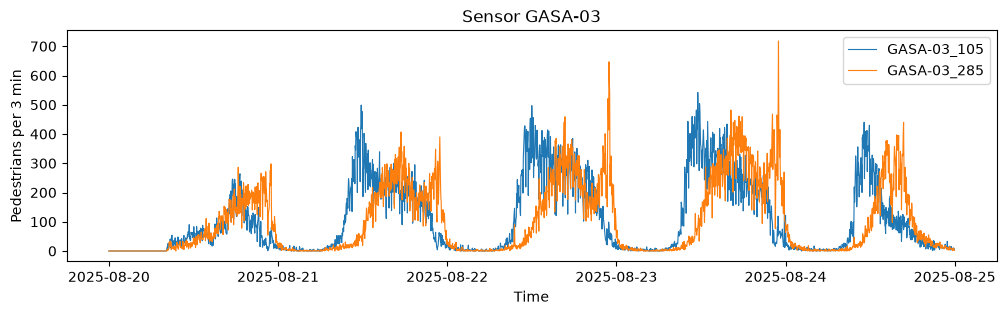

In [29]:
plot_sensor('GASA-03')        # referentie: een "normale" sensor in het SAIL-gebied

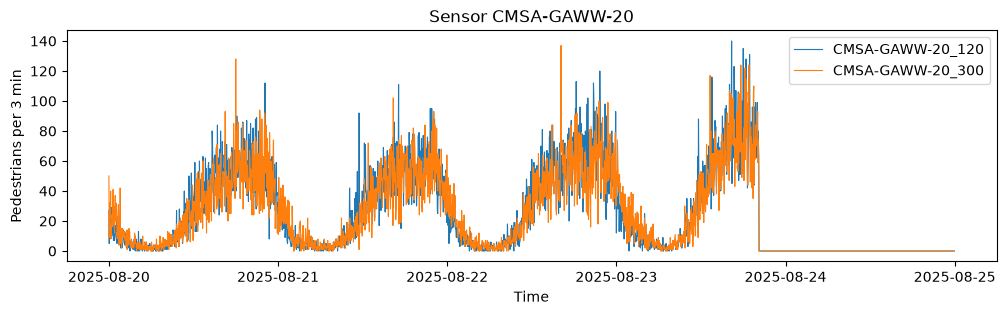

In [30]:
plot_sensor('CMSA-GAWW-20')

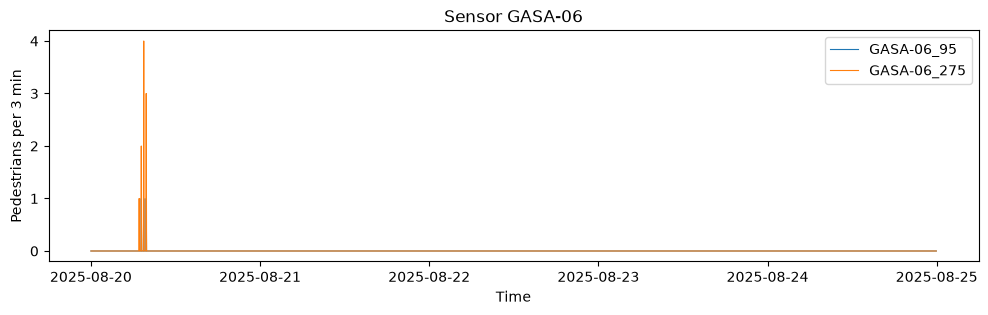

In [31]:
plot_sensor('GASA-06')

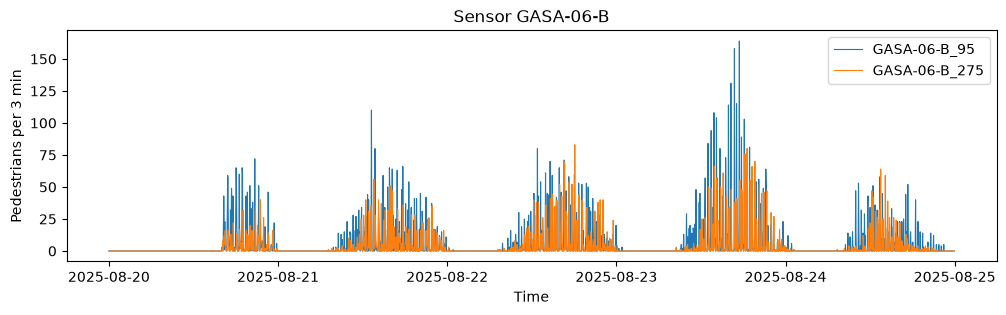

In [32]:
plot_sensor('GASA-06-B')

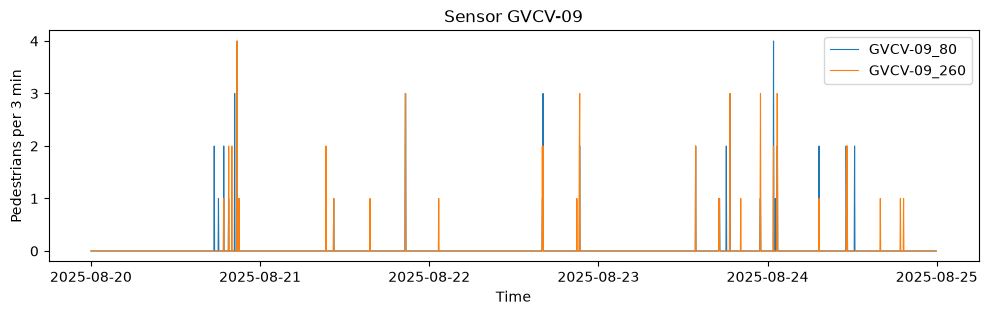

In [33]:
plot_sensor('GVCV-09')

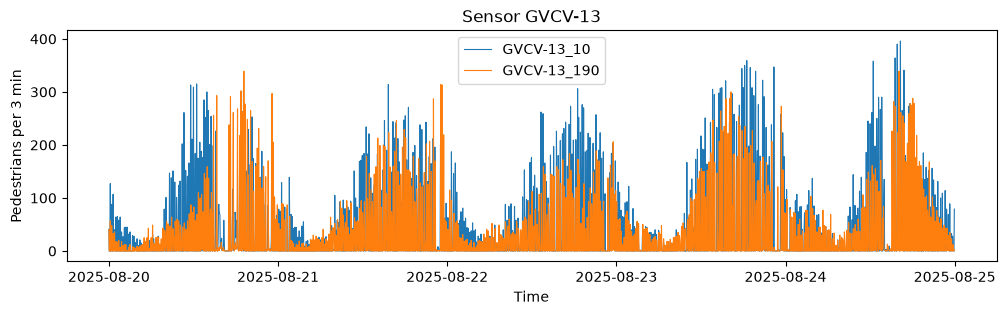

In [34]:
plot_sensor('GVCV-13')        # een veerpont-sensor

**Findings – unusual values and sensor malfunctions**

- **No negative values** were found.
- Most sensors show a clear daily pattern (low at night, high during the day). At GASA-03 the two directions 
  peak at different times: towards the event area during the day (ingress) and back towards Central Station 
  in the evening (egress).
- **Ferry sensors (GVCV)** contain many zeros (60–80%) alternating with high peaks. This reflects ferries 
  arriving and unloading passengers in groups, and is **not** an error.
- **CMSA-GAWW-20** (Oudebrugsteeg) shows a normal pattern until the evening of 23 August, after which it 
  suddenly drops to 0 for the rest of the event → **sensor failure**.
- **GASA-06** recorded only 13 pedestrians in total (morning of 20 August) and zero afterwards → **not working**.
- **GASA-06-B** starts recording on 20 August around 16:00 and shows a normal pattern afterwards. It is not 
  listed in `sensor-location.xlsx`, while GASA-06 is listed as "Azartplein B". GASA-06-B is therefore most 
  likely the replacement sensor at the same location.
- **GVCV-09** (Zeeburg) records only a few pedestrians per day (max. 4 per 3 min) and contains no 
  useful information for crowd monitoring.
- Several SAIL-area sensors (GASA) record zero until the morning of 20 August, suggesting they were switched 
  on at the start of the event.

### 5B. Cleaning decisions
Based on the findings above, the following cleaning steps are applied:
1. **GASA-06** and **GVCV-09** are removed: GASA-06 did not work, and GVCV-09 contains no useful information.
2. For **CMSA-GAWW-20**, all values after the sensor failure on 23 August are set to **missing (NaN)** instead of 0, 
   because the true number of pedestrians is unknown. The data before the failure is kept.
3. **GASA-06-B** and the ferry sensors (GVCV) are kept unchanged.

In [35]:
df_clean = df.copy()

In [36]:
gaww20_cols = ['CMSA-GAWW-20_120', 'CMSA-GAWW-20_300']

last_count = df.loc[df[gaww20_cols].sum(axis=1) > 0, 'timestamp'].max()
outage_start = last_count + pd.Timedelta(minutes=3)

print("Last measurement > 0:", last_count)
print("Start of sensor failure:", outage_start)

Last measurement > 0: 2025-08-23 20:12:00+02:00
Start of sensor failure: 2025-08-23 20:15:00+02:00


In [37]:
df.loc[(df['timestamp'] >= '2025-08-23 20:00') & (df['timestamp'] <= '2025-08-23 20:30'), 
       ['timestamp'] + gaww20_cols]

,timestamp,CMSA-GAWW-20_120,CMSA-GAWW-20_300
1840,2025-08-23 20:00:00+02:00,99,87
1841,2025-08-23 20:03:00+02:00,59,93
1842,2025-08-23 20:06:00+02:00,80,59
1843,2025-08-23 20:09:00+02:00,70,74
1844,2025-08-23 20:12:00+02:00,63,46
1845,2025-08-23 20:15:00+02:00,0,0
1846,2025-08-23 20:18:00+02:00,0,0
1847,2025-08-23 20:21:00+02:00,0,0
1848,2025-08-23 20:24:00+02:00,0,0
1849,2025-08-23 20:27:00+02:00,0,0


In [38]:
sensors_to_remove = ['GASA-06', 'GVCV-09']

cols_to_remove = [col for col in sensor_cols if col.split('_')[0] in sensors_to_remove]
print("Columns removed:", cols_to_remove)

df_clean = df_clean.drop(columns=cols_to_remove)

Columns removed: ['GASA-06_95', 'GASA-06_275', 'GVCV-09_80', 'GVCV-09_260']


In [39]:
import numpy as np

df_clean.loc[df_clean['timestamp'] >= outage_start, gaww20_cols] = np.nan

In [40]:
sensor_cols_clean = [col for col in df_clean.columns if col not in time_cols and col != 'timestamp']

print("Shape before:", df.shape)
print("Shape after: ", df_clean.shape)
print("Sensor columns:", len(sensor_cols_clean))
print("Unique sensors:", len(set(col.split('_')[0] for col in sensor_cols_clean)))
print("GASA-06-B still present:", 'GASA-06-B_95' in df_clean.columns)
print("Missing values per GAWW-20 column:")
print(df_clean[gaww20_cols].isna().sum())

Shape before: (2400, 81)
Shape after:  (2400, 77)
Sensor columns: 70
Unique sensors: 35
GASA-06-B still present: True
Missing values per GAWW-20 column:
CMSA-GAWW-20_120    555
CMSA-GAWW-20_300    555
dtype: int64


In [41]:
def plot_sensor(sensor, data=df):
    """Plot both walking directions of one sensor over the whole event."""
    columns = [col for col in data.columns if col.startswith(sensor + '_')]
    
    fig, ax = plt.subplots(figsize=(12, 3))
    for col in columns:
        ax.plot(data['timestamp'], data[col], label=col, linewidth=0.8)
    
    ax.set_title(f"Sensor {sensor}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Pedestrians per 3 min")
    ax.legend()
    ax.set_xlim(data['timestamp'].min(), data['timestamp'].max())
    plt.show()

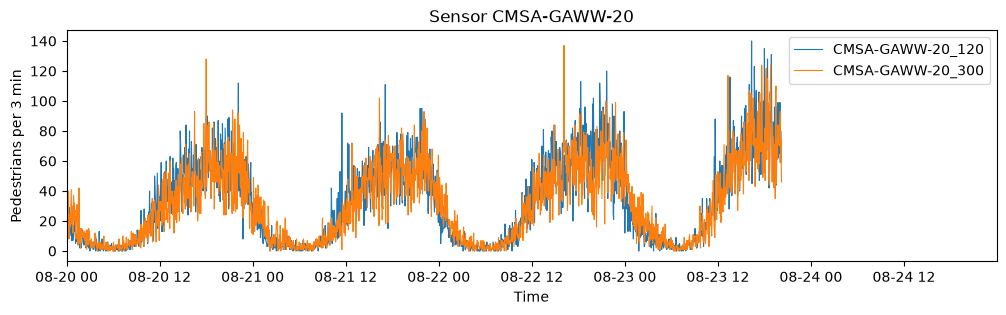

In [42]:
plot_sensor('CMSA-GAWW-20', data=df_clean)

**Result of cleaning step 5B**

- The last valid measurement of **CMSA-GAWW-20** was on 23 August 2025 at 20:12; from **20:15 onwards** 
  (555 intervals, 27.75 hours) both directions were set to missing (NaN).
- **GASA-06** and **GVCV-09** (4 columns) were removed.
- The cleaned dataset `df_clean` contains **2400 rows, 70 sensor columns and 35 sensors**. 
  The original data (`df`) is kept unchanged for comparison.
- Note for further analysis: CMSA-GAWW-20 has no data for Sunday 24 August. Daily comparisons 
  for this location should therefore only use 20–23 August.

## 6. Checking sensor IDs against the location file
To make sure the cleaned count data can be linked to the sensor locations (done in `sensor-location_cleaned.ipynb`), 
we check whether the sensor IDs in the count data match the IDs in `sensor-location.xlsx`.

In [44]:
loc = pd.read_excel("../Data/sensor-location.xlsx")

sensors_data = set(col.split('_')[0] for col in sensor_cols_clean)
sensors_loc = set(loc.iloc[:, 0].str.strip())

print("In both files:        ", len(sensors_data & sensors_loc))
print("Only in count data:   ", sensors_data - sensors_loc)
print("Only in location file:", sensors_loc - sensors_data)

In both files:         34
Only in count data:    {'GASA-06-B'}
Only in location file: {'GVCV-09', 'GASA-06'}


**Findings – sensor IDs**

- **34 of the 35** sensors in the cleaned count data have a matching ID in the location file.
- **GASA-06** and **GVCV-09** only appear in the location file, because they were removed from the count data in step 5B. 
  They can be ignored when linking.
- **GASA-06-B** has no row in the location file. Since GASA-06 is listed as "Azartplein B" and GASA-06-B started 
  recording when GASA-06 stopped (step 5A), GASA-06-B is most likely the replacement sensor at the same location. 
  → *To be handled in `sensor-location_cleaned.ipynb`: assign the location of GASA-06 to GASA-06-B (assumption, to be confirmed).*